# From predictions to a retention decision

Notebook 1 built the churn model. This notebook asks the business question: **if the team can only contact *k* customers, who should it call, and does it pay off?**

Two steps:
1. Check whether the model's probabilities are trustworthy, and calibrate them if not.
2. Backtest three contact strategies on the held-out test set, using each customer's real outcome.

Assumptions (set below, change them and re-run): a contact costs $20, and a retention offer saves 30% of customers who would otherwise leave. These are placeholders, not measured values. `CLTV` is IBM's synthetic customer lifetime value. It is used only as the revenue at stake and never as a model feature.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score
from src.etl import extract
from src.pipeline import split_test
from src.retention import backtest, random_backtest
sns.set_theme(style='whitegrid'); SEED = 42
SAVE_RATE, COST = 0.30, 20.0

df = pd.read_csv('../data/processed/churn.csv')
X_tv, X_test, y_tv, y_test = split_test(df)  # the same function notebook 1 uses
art = joblib.load('../models/best_model.pkl'); cols = art['columns']
cltv = extract()['status'].set_index('Customer ID')['CLTV'].reindex(X_test['Customer ID']).values
print('test rows:', len(X_test), '| churn rate: %.3f' % y_test.mean(), '| mean CLTV: $%.0f' % cltv.mean())

test rows: 1409 | churn rate: 0.265 | mean CLTV: $4394


## 1. Are the probabilities honest?
The model was trained with class weights, which pushes scores up. Ranking (AUC) is unaffected, but a score of 0.6 should mean about 60% of such customers churn, or dollar estimates will be inflated.

In [2]:
raw = art['pipeline'].predict_proba(X_test[cols])[:, 1]
cal = CalibratedClassifierCV(clone(art['pipeline']), method='sigmoid', cv=5).fit(X_tv[cols], y_tv)  # internal CV on train+val only
cp = cal.predict_proba(X_test[cols])[:, 1]
res = pd.DataFrame({'AUC': [roc_auc_score(y_test, raw), roc_auc_score(y_test, cp)],
                    'Brier (lower is better)': [brier_score_loss(y_test, raw), brier_score_loss(y_test, cp)],
                    'mean predicted churn': [raw.mean(), cp.mean()]}, index=['as trained', 'calibrated']).round(4)
res.loc['actual churn rate'] = [np.nan, np.nan, round(y_test.mean(), 4)]
res

,AUC,Brier (lower is better),mean predicted churn
as trained,0.9128,0.1225,0.3751
calibrated,0.9134,0.1043,0.2650
actual churn rate,NaN,NaN,0.2654


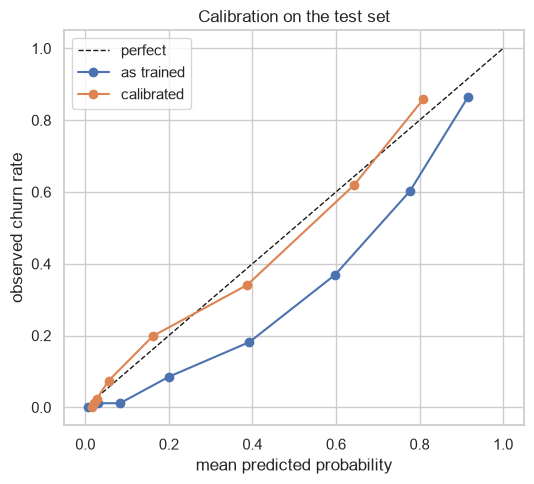

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
for p, name in ((raw, 'as trained'), (cp, 'calibrated')):
    f, m = calibration_curve(y_test, p, n_bins=8, strategy='quantile'); ax.plot(m, f, 'o-', label=name)
ax.set(xlabel='mean predicted probability', ylabel='observed churn rate', title='Calibration on the test set'); ax.legend()
plt.tight_layout(); plt.savefig('../reports/calibration.png', dpi=130); plt.show()

## 2. Who should the team contact?
Three strategies, each given a budget of *k* contacts:
- **Random**: average of 500 random draws.
- **Highest churn probability**: call the likeliest leavers.
- **Highest expected loss**: rank by `probability x CLTV`, so a likely leaver with high value comes before a likely leaver with low value.

Net value = `save rate x CLTV of contacted customers who really churned - k x cost per contact`. It uses actual outcomes, so luck is not hidden.

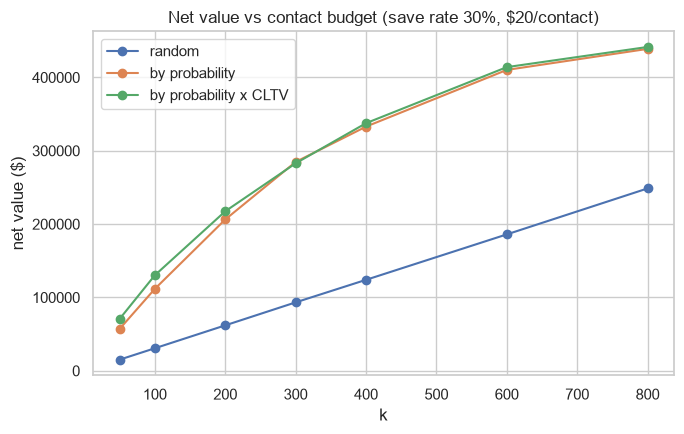

,random,by probability,by probability x CLTV
k,,,
50,15167.0,57137.0,70755.0
100,30698.0,111664.0,130243.0
200,61912.0,206250.0,217426.0
300,93246.0,284714.0,282842.0
400,123986.0,332870.0,337565.0
600,185950.0,410197.0,413995.0
800,248616.0,438870.0,441478.0


In [4]:
ks = [50, 100, 200, 300, 400, 600, 800]
rows = []
for k in ks:
    rows.append({'k': k,
                 'random': random_backtest(y_test.values, cltv, k, SAVE_RATE, COST),
                 'by probability': backtest(y_test.values, cltv, cp, k, SAVE_RATE, COST),
                 'by probability x CLTV': backtest(y_test.values, cltv, cp * cltv, k, SAVE_RATE, COST)})
bt = pd.DataFrame(rows).set_index('k').round(0)
ax = bt.plot(marker='o', figsize=(7, 4.5), title=f'Net value vs contact budget (save rate {SAVE_RATE:.0%}, ${COST:.0f}/contact)')
ax.set(ylabel='net value ($)'); plt.tight_layout(); plt.savefig('../reports/retention.png', dpi=130); plt.show()
bt

In [5]:
ev = cp * cltv
ks_all = np.arange(0, len(ev) + 1, 10)
curve = np.array([backtest(y_test.values, cltv, ev, k, SAVE_RATE, COST) for k in ks_all])
ceiling = SAVE_RATE * (y_test.values * cltv).sum()
print('realized peak: k = %d, net $%.0f' % (ks_all[curve.argmax()], curve.max()))
print('ceiling (save %.0f%% of every churner, zero contact cost): $%.0f' % (SAVE_RATE * 100, ceiling))
print('customers whose expected saving exceeds the contact cost:', int((ev * SAVE_RATE > COST).sum()), 'of', len(ev))

realized peak: k = 960, net $444707
ceiling (save 30% of every churner, zero contact cost): $466908
customers whose expected saving exceeds the contact cost: 1334 of 1409


## 3. How sensitive is this to the assumptions?
The save rate and contact cost are guesses. At $20 per contact almost any contact pays off, so the grid goes up to $600 where targeting starts to matter. This grid shows the net value of the best strategy at k = 300 across plausible values.

In [6]:
grid = pd.DataFrame({f'cost ${c}': {f'save {s:.0%}': backtest(y_test.values, cltv, cp * cltv, 300, s, c) for s in (0.05, 0.1, 0.2, 0.3, 0.5)} for c in (20, 100, 300, 600)}).round(0)
grid

,cost $20,cost $100,cost $300,cost $600
save 5%,42140.0,18140.0,-41860.0,-131860.0
save 10%,90281.0,66281.0,6281.0,-83719.0
save 20%,186561.0,162561.0,102561.0,12561.0
save 30%,282842.0,258842.0,198842.0,108842.0
save 50%,475403.0,451403.0,391403.0,301403.0


## 4. Takeaways

- **Probabilities were inflated.** Class weights pushed the mean predicted churn to 0.375 against an actual 0.265. Sigmoid calibration fixed it (Brier 0.1225 to 0.1043, mean 0.265) and left AUC unchanged (0.913).
- **Targeting beats random by about 3x.** Contacting the 300 highest-scored customers (21% of the test set) nets about $283k, against $93k for 300 random contacts.
- **Weighting by CLTV helps only on small budgets.** Over ranking by probability alone it adds 24% at k=50, 17% at k=100, 5% at k=200, and under 1.5% from k=300 up.
- **At $20 a contact, almost everyone is worth calling.** 1,334 of 1,409 customers have an expected saving above the contact cost. The realized peak is k=960 at $445k, 95% of the $467k ceiling. That peak was found on the test set, so treat it as optimistic.
- **The conclusion depends on two guesses.** At k=300, a 5% save rate loses money once a contact costs $300, and a 10% save rate loses money at $600. Measure the real save rate with a small A/B test before trusting the dollar figures.

Limits: one test split of 1,409 customers, CLTV is IBM's synthetic field, and the cost and save rate are placeholders.

In [7]:
bt.to_csv('../reports/retention_backtest.csv'); res.to_csv('../reports/calibration.csv')
print('saved')

saved
